# SAT-Dengue V2 — Stage 2 Official EDA (Increment 01)

## Objective
Perform a reproducible, bounded initial EDA focused on:
- `data/raw/dengue.csv`
- `data/raw/dengue_grave.csv`

And only complementary coverage/missingness review on:
- `data/raw/google_earth_engine.csv`

## Approved decisions used in this notebook
- Epidemiological geography: **residence** fields.
- Epidemiological date candidate: **`INI_SIN`** (onset of symptoms), without automatic substitution by `FEC_NOT`.
- Geographic scope: municipalities belonging to **Tolima** and **Meta** by residence.
- Descriptive unit: **municipality-month**, keeping dengue and severe dengue files separate.

## Scope boundary
This notebook does not close Stage 2 and does not approve G2 (Data & Target Freeze).

## Norms Applied (norm → application → evidence)

| Norm | Application in this notebook | Evidence in this notebook |
|---|---|---|
| `AGENTS.md` + `docs/README.md` | Authority hierarchy respected, Stage 2 bounded scope, no direct product implementation. | Scope and stop-point sections; no model training cells. |
| `docs/standards/ml-scientific-standards.md` | Reproducible exploratory notebook, temporal-leakage awareness, exploration separated from production logic. | Deterministic parameters, explicit assumptions/limitations, no production pipeline code. |
| `docs/standards/engineering-standards.md` | Explicit configuration, readable Python, traceable outputs. | Parameter cell, helper functions, summary tables and plots with clear denominators. |
| `docs/data/data-policy.md` + `docs/SECURITY.md` | Read-only use of original data and no sensitive row-level output exposure. | Aggregated outputs only, no individual records printed. |
| `docs/methodology/crisp-mlq-framework.md` | Data-understanding work only, no preparation/modeling phases executed. | Notebook sections restricted to structure/quality/coverage diagnostics. |
| `docs/operations/validation-and-evidence.md` | Evidence states explicitly tracked. | Final evidence-state table (PASS/FAIL/BLOCKED/UNVERIFIED). |
| `docs/TESTING_GUIDE.md` + `docs/DEVELOPMENT_COMMANDS.md` | Applicable repo validations run and reported outside notebook after edits. | Session validation log and final summary. |

In [12]:
from __future__ import annotations

from pathlib import Path
from collections import Counter, defaultdict
import unicodedata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 200)
pd.set_option("display.max_rows", 200)

ANALYSIS_CUTOFF_DATE = pd.Timestamp.today().normalize()
TARGET_DPTO_CODES = {"50": "META", "73": "TOLIMA"}
TARGET_DPTO_NAMES = {"META", "TOLIMA"}

EPIDEMIOLOGICAL_USECOLS = [
    "CONSECUTIVE", "COD_EVE", "FEC_NOT", "INI_SIN", "SEMANA", "ANO",
    "COD_DPTO_R", "COD_MUN_R", "Departamento_residencia", "Municipio_residencia",
]

CLIMATE_USECOLS = [
    "date", "dpto_ccdgo", "dpto_cnmbr", "mpio_cdpmp", "mpio_cnmbr",
    "rain_mm_day", "temp_mean_c", "dewpoint_mean_c", "soil_water_l1_mean",
    "surface_runoff_mm_day", "total_evaporation_mm_day_ecmwf", "wind_u_mean_ms",
    "wind_v_mean_ms", "solar_radiation_mj_m2_day",
]

CLIMATE_VARS = [
    "rain_mm_day", "temp_mean_c", "dewpoint_mean_c", "soil_water_l1_mean",
    "surface_runoff_mm_day", "total_evaporation_mm_day_ecmwf", "wind_u_mean_ms",
    "wind_v_mean_ms", "solar_radiation_mj_m2_day",
]

print("Analysis cutoff date:", ANALYSIS_CUTOFF_DATE.date())

Analysis cutoff date: 2026-10-15


In [13]:
import sys


def find_repo_root(start: Path) -> Path:
    current = start.resolve()
    for candidate in [current, *current.parents]:
        if (candidate / "pyproject.toml").exists() and (candidate / "AGENTS.md").exists():
            return candidate
    raise FileNotFoundError("Could not resolve repository root from current notebook location.")

repo_root = find_repo_root(Path.cwd())

data_paths = {
    "dengue": repo_root / "data" / "raw" / "dengue.csv",
    "dengue_grave": repo_root / "data" / "raw" / "dengue_grave.csv",
    "climate": repo_root / "data" / "raw" / "google_earth_engine.csv",
}

for name, path in data_paths.items():
    if not path.exists():
        raise FileNotFoundError(f"Missing required input file: {path}")

file_meta = []
for name, path in data_paths.items():
    stat = path.stat()
    file_meta.append(
        {
            "dataset": name,
            "relative_path": str(path.relative_to(repo_root)),
            "size_bytes": stat.st_size,
            "size_mb": round(stat.st_size / (1024 ** 2), 2),
            "modified_local": pd.Timestamp(stat.st_mtime, unit="s").tz_localize("UTC").tz_convert("America/Bogota"),
        }
    )

meta_df = pd.DataFrame(file_meta)
display(Markdown("### Environment and provenance"))
display(pd.DataFrame({
    "item": ["repo_root", "notebook_path", "analysis_cutoff_date", "python_version", "pandas_version"],
    "value": [
        str(repo_root),
        "notebooks/01_stage2_residence_onset_eda.ipynb",
        str(ANALYSIS_CUTOFF_DATE.date()),
        sys.version.split(" ")[0],
        pd.__version__,
    ],
}))

display(meta_df)

### Environment and provenance

,item,value
0,repo_root,/Users/mauriciorodriguez/Projects/AI-Masters/S...
1,notebook_path,notebooks/01_stage2_residence_onset_eda.ipynb
2,analysis_cutoff_date,2026-10-15
3,python_version,3.12.11
4,pandas_version,3.0.6


,dataset,relative_path,size_bytes,size_mb,modified_local
0,dengue,data/raw/dengue.csv,875694283,835.13,2026-10-15 18:17:22.588384628-05:00
1,dengue_grave,data/raw/dengue_grave.csv,24537734,23.40,2026-10-15 18:17:22.133687258-05:00
2,climate,data/raw/google_earth_engine.csv,1714041810,1634.64,2026-10-15 18:17:23.483286381-05:00


In [14]:
def read_header(path: Path) -> list[str]:
    return pd.read_csv(path, nrows=0).columns.tolist()

headers = {name: read_header(path) for name, path in data_paths.items()}

header_df = pd.DataFrame(
    [{"dataset": name, "columns": len(cols), "column_names": cols} for name, cols in headers.items()]
)

display(Markdown("### Header inspection"))
display(header_df[["dataset", "columns"]])

expected_epi_fields = [
    "INI_SIN", "FEC_NOT", "ANO", "SEMANA", "COD_DPTO_R", "COD_MUN_R",
    "Departamento_residencia", "Municipio_residencia", "COD_EVE", "CONSECUTIVE",
]

field_correspondence = pd.DataFrame({
    "field": expected_epi_fields,
    "present_in_dengue": [f in headers["dengue"] for f in expected_epi_fields],
    "present_in_dengue_grave": [f in headers["dengue_grave"] for f in expected_epi_fields],
    "official_mapping_status": [
        "pending_full_69_column_mapping" for _ in expected_epi_fields
    ],
})

display(Markdown("### Priority epidemiological field correspondence status"))
display(field_correspondence)

expected_climate_fields = [
    "date", "year", "month", "day_of_year", "dpto_ccdgo", "dpto_cnmbr",
    "mpio_ccdgo", "mpio_cdpmp", "mpio_cnmbr", *CLIMATE_VARS,
]
climate_field_df = pd.DataFrame({
    "field": expected_climate_fields,
    "present_in_climate_csv": [f in headers["climate"] for f in expected_climate_fields],
})

display(Markdown("### Climate field presence check"))
display(climate_field_df)

### Header inspection

,dataset,columns
0,dengue,69
1,dengue_grave,69
2,climate,18


### Priority epidemiological field correspondence status

,field,present_in_dengue,present_in_dengue_grave,official_mapping_status
0,INI_SIN,True,True,pending_full_69_column_mapping
1,FEC_NOT,True,True,pending_full_69_column_mapping
2,ANO,True,True,pending_full_69_column_mapping
3,SEMANA,True,True,pending_full_69_column_mapping
4,COD_DPTO_R,True,True,pending_full_69_column_mapping
5,COD_MUN_R,True,True,pending_full_69_column_mapping
6,Departamento_residencia,True,True,pending_full_69_column_mapping
7,Municipio_residencia,True,True,pending_full_69_column_mapping
8,COD_EVE,True,True,pending_full_69_column_mapping
9,CONSECUTIVE,True,True,pending_full_69_column_mapping


### Climate field presence check

,field,present_in_climate_csv
0,date,True
1,year,True
2,month,True
3,day_of_year,True
4,dpto_ccdgo,True
5,dpto_cnmbr,True
6,mpio_ccdgo,True
7,mpio_cdpmp,True
8,mpio_cnmbr,True
9,rain_mm_day,True


In [15]:
def normalize_text_series(series: pd.Series) -> pd.Series:
    s = series.fillna("").astype(str)
    s = s.str.replace("\xa0", " ", regex=False).str.strip()
    return s


def normalize_name_series(series: pd.Series) -> pd.Series:
    s = normalize_text_series(series).str.upper()
    s = s.str.normalize("NFKD").str.encode("ascii", errors="ignore").str.decode("ascii")
    return s


def parse_colombian_datetime(series: pd.Series) -> tuple[pd.Series, pd.Series, pd.Series]:
    s = normalize_text_series(series)
    s = (
        s.str.replace("a. m.", "", regex=False)
         .str.replace("p. m.", "", regex=False)
         .str.replace("a. m", "", regex=False)
         .str.replace("p. m", "", regex=False)
         .str.replace("AM", "", regex=False)
         .str.replace("PM", "", regex=False)
         .str.strip()
    )
    date_part = s.str.split(" ").str[0]
    dt = pd.to_datetime(date_part, format="%d/%m/%Y", errors="coerce")
    is_missing = s.eq("") | s.str.lower().isin({"nan", "none", "nat"})
    is_valid = dt.notna()
    is_invalid = (~is_missing) & (~is_valid)
    return dt, is_missing, is_invalid


def analyze_epidemiological_file(path: Path, dataset_name: str, chunk_size: int = 200_000):
    balance = Counter()
    quality = defaultdict(Counter)
    weekly_consistency = defaultdict(Counter)
    delay_samples = defaultdict(list)

    municipal = defaultdict(lambda: {
        "records_total": 0,
        "records_valid_ini_sin": 0,
        "records_missing_ini_sin": 0,
        "records_invalid_ini_sin": 0,
        "first_valid_ini_sin": None,
        "last_valid_ini_sin": None,
        "months_with_valid_ini_sin": set(),
    })

    monthly_valid_counter = Counter()
    temporal_problem_counter = Counter()
    validated_scope_mpio_codes = set()

    global_min_valid_ini = None
    global_max_valid_ini = None

    reader = pd.read_csv(
        path,
        usecols=EPIDEMIOLOGICAL_USECOLS,
        dtype=str,
        chunksize=chunk_size,
        low_memory=True,
    )

    for chunk in reader:
        balance["records_total"] += len(chunk)

        dept_code = normalize_text_series(chunk["COD_DPTO_R"]).str.zfill(2).str[-2:]
        mun_code = normalize_text_series(chunk["COD_MUN_R"]).str.zfill(3).str[-3:]
        dept_name = normalize_name_series(chunk["Departamento_residencia"])
        mun_name = normalize_name_series(chunk["Municipio_residencia"])

        full_mpio_code = dept_code + mun_code

        in_scope_by_code = dept_code.isin(TARGET_DPTO_CODES.keys())
        in_scope_by_name = dept_name.isin(TARGET_DPTO_NAMES)
        in_scope = in_scope_by_code | in_scope_by_name

        has_residence_reference = dept_code.ne("") | dept_name.ne("")
        indeterminate_residence = (~in_scope) & (
            (~has_residence_reference)
            | dept_code.eq("00")
            | dept_name.str.contains("DESCONOCIDO", na=False)
            | mun_name.str.contains("DESCONOCIDO", na=False)
        )
        outside_scope = (~in_scope) & (~indeterminate_residence)

        balance["records_in_scope_residence"] += int(in_scope.sum())
        balance["records_outside_scope_residence"] += int(outside_scope.sum())
        balance["records_indeterminate_residence"] += int(indeterminate_residence.sum())

        dept_label = dept_code.map(TARGET_DPTO_CODES)
        dept_label = dept_label.fillna(dept_name.where(dept_name.isin(TARGET_DPTO_NAMES), "OUT_OF_SCOPE"))

        ini_dt, ini_missing, ini_invalid = parse_colombian_datetime(chunk["INI_SIN"])
        fec_not_dt, _, _ = parse_colombian_datetime(chunk["FEC_NOT"])
        fec_valid = fec_not_dt.notna()

        scoped_df = pd.DataFrame(
            {
                "dept": dept_label,
                "full_mpio_code": full_mpio_code,
                "mun_name": mun_name,
                "ini_dt": ini_dt,
                "ini_missing": ini_missing,
                "ini_invalid": ini_invalid,
                "ini_valid": ini_dt.notna(),
                "fec_not_dt": fec_not_dt,
                "fec_not_valid": fec_valid,
                "ano": pd.to_numeric(chunk["ANO"], errors="coerce"),
                "semana": pd.to_numeric(chunk["SEMANA"], errors="coerce"),
            }
        )

        scoped_df = scoped_df[in_scope].copy()

        if scoped_df.empty:
            continue

        for dept in ["META", "TOLIMA"]:
            dept_mask = scoped_df["dept"] == dept
            if not dept_mask.any():
                continue

            dept_df = scoped_df[dept_mask]
            q = quality[dept]
            q["records_in_scope"] += len(dept_df)
            q["ini_valid"] += int(dept_df["ini_valid"].sum())
            q["ini_missing"] += int(dept_df["ini_missing"].sum())
            q["ini_invalid"] += int(dept_df["ini_invalid"].sum())
            q["ini_future_vs_cutoff"] += int((dept_df["ini_dt"] > ANALYSIS_CUTOFF_DATE).sum())

            comparable_delay = dept_df["ini_valid"] & dept_df["fec_not_valid"]
            delay_days = (dept_df["fec_not_dt"] - dept_df["ini_dt"]).dt.days
            q["delay_comparable_pairs"] += int(comparable_delay.sum())
            q["ini_after_fec_not"] += int(((dept_df["ini_dt"] > dept_df["fec_not_dt"]) & comparable_delay).sum())
            delay_samples[dept].extend(delay_days[comparable_delay].dropna().astype(int).tolist())

            comparable_epi = dept_df["ini_valid"] & dept_df["ano"].notna() & dept_df["semana"].notna()
            iso = dept_df["ini_dt"].dt.isocalendar()
            weekly_consistency[dept]["comparables"] += int(comparable_epi.sum())
            weekly_consistency[dept]["ano_matches_iso_year"] += int(((dept_df["ano"] == iso.year) & comparable_epi).sum())
            weekly_consistency[dept]["semana_matches_iso_week"] += int(((dept_df["semana"] == iso.week) & comparable_epi).sum())

            valid_rows = dept_df[dept_df["ini_valid"]].copy()
            if not valid_rows.empty:
                current_min = valid_rows["ini_dt"].min()
                current_max = valid_rows["ini_dt"].max()
                global_min_valid_ini = current_min if global_min_valid_ini is None else min(global_min_valid_ini, current_min)
                global_max_valid_ini = current_max if global_max_valid_ini is None else max(global_max_valid_ini, current_max)

                valid_rows["month"] = valid_rows["ini_dt"].dt.to_period("M").astype(str)
                month_counts = valid_rows.groupby(["dept", "month"], observed=True).size()
                for (d, m), value in month_counts.items():
                    monthly_valid_counter[(d, m)] += int(value)

                for code in valid_rows["full_mpio_code"].unique():
                    if code and code != "00000":
                        validated_scope_mpio_codes.add(code)

            status_rows = dept_df[(dept_df["ini_missing"] | dept_df["ini_invalid"]) & dept_df["fec_not_valid"]].copy()
            if not status_rows.empty:
                status_rows["problem_status"] = np.where(status_rows["ini_missing"], "missing", "invalid")
                status_rows["fec_month"] = status_rows["fec_not_dt"].dt.to_period("M").astype(str)
                grouped_problems = status_rows.groupby(["dept", "fec_month", "problem_status"], observed=True).size()
                for key, value in grouped_problems.items():
                    temporal_problem_counter[key] += int(value)

        grouped = scoped_df.groupby(["dept", "full_mpio_code", "mun_name"], observed=True)
        for key, subdf in grouped:
            state = municipal[key]
            state["records_total"] += len(subdf)
            state["records_valid_ini_sin"] += int(subdf["ini_valid"].sum())
            state["records_missing_ini_sin"] += int(subdf["ini_missing"].sum())
            state["records_invalid_ini_sin"] += int(subdf["ini_invalid"].sum())

            valid_sub = subdf[subdf["ini_valid"]]
            if not valid_sub.empty:
                min_valid = valid_sub["ini_dt"].min()
                max_valid = valid_sub["ini_dt"].max()
                state["first_valid_ini_sin"] = min_valid if state["first_valid_ini_sin"] is None else min(state["first_valid_ini_sin"], min_valid)
                state["last_valid_ini_sin"] = max_valid if state["last_valid_ini_sin"] is None else max(state["last_valid_ini_sin"], max_valid)
                state["months_with_valid_ini_sin"].update(valid_sub["ini_dt"].dt.to_period("M").astype(str).unique())

    balance_df = pd.DataFrame(
        [
            {
                "dataset": dataset_name,
                "records_total": balance["records_total"],
                "records_in_scope_residence": balance["records_in_scope_residence"],
                "records_outside_scope_residence": balance["records_outside_scope_residence"],
                "records_indeterminate_residence": balance["records_indeterminate_residence"],
            }
        ]
    )

    quality_rows = []
    delay_rows = []
    for dept in ["META", "TOLIMA"]:
        q = quality[dept]
        denominator = q["records_in_scope"] if q["records_in_scope"] else np.nan
        quality_rows.append(
            {
                "dataset": dataset_name,
                "department": dept,
                "records_in_scope": q["records_in_scope"],
                "ini_valid_count": q["ini_valid"],
                "ini_missing_count": q["ini_missing"],
                "ini_invalid_count": q["ini_invalid"],
                "ini_valid_pct": q["ini_valid"] / denominator if denominator == denominator else np.nan,
                "ini_missing_pct": q["ini_missing"] / denominator if denominator == denominator else np.nan,
                "ini_invalid_pct": q["ini_invalid"] / denominator if denominator == denominator else np.nan,
                "ini_future_vs_cutoff_count": q["ini_future_vs_cutoff"],
                "ini_after_fec_not_count": q["ini_after_fec_not"],
                "delay_comparable_pairs": q["delay_comparable_pairs"],
            }
        )

        delays = pd.Series(delay_samples[dept], dtype="float")
        if len(delays) == 0:
            delay_rows.append(
                {
                    "dataset": dataset_name,
                    "department": dept,
                    "delay_pairs": 0,
                    "negative_delay_count": 0,
                    "negative_delay_pct": np.nan,
                    "median_non_negative_delay_days": np.nan,
                    "p90_non_negative_delay_days": np.nan,
                }
            )
        else:
            non_negative = delays[delays >= 0]
            negative_count = int((delays < 0).sum())
            delay_rows.append(
                {
                    "dataset": dataset_name,
                    "department": dept,
                    "delay_pairs": int(len(delays)),
                    "negative_delay_count": negative_count,
                    "negative_delay_pct": negative_count / len(delays),
                    "median_non_negative_delay_days": float(non_negative.median()) if len(non_negative) else np.nan,
                    "p90_non_negative_delay_days": float(non_negative.quantile(0.9)) if len(non_negative) else np.nan,
                }
            )

    weekly_rows = []
    for dept in ["META", "TOLIMA"]:
        w = weekly_consistency[dept]
        comparables = w["comparables"]
        weekly_rows.append(
            {
                "dataset": dataset_name,
                "department": dept,
                "comparables": comparables,
                "ano_matches_iso_year": w["ano_matches_iso_year"],
                "semana_matches_iso_week": w["semana_matches_iso_week"],
                "ano_match_rate": (w["ano_matches_iso_year"] / comparables) if comparables else np.nan,
                "semana_match_rate": (w["semana_matches_iso_week"] / comparables) if comparables else np.nan,
                "note": "Descriptive check against ISO week-year; official rule harmonization remains pending.",
            }
        )

    municipal_rows = []
    for (dept, code, muni_name), state in municipal.items():
        municipal_rows.append(
            {
                "dataset": dataset_name,
                "department": dept,
                "municipality_code_full": code,
                "municipality_name_residence": muni_name,
                "records_total": state["records_total"],
                "records_valid_ini_sin": state["records_valid_ini_sin"],
                "records_missing_ini_sin": state["records_missing_ini_sin"],
                "records_invalid_ini_sin": state["records_invalid_ini_sin"],
                "first_valid_ini_sin": state["first_valid_ini_sin"],
                "last_valid_ini_sin": state["last_valid_ini_sin"],
                "months_with_valid_ini_sin": len(state["months_with_valid_ini_sin"]),
            }
        )

    municipal_df = pd.DataFrame(municipal_rows)

    if global_min_valid_ini is not None and global_max_valid_ini is not None:
        window_months = pd.period_range(global_min_valid_ini.to_period("M"), global_max_valid_ini.to_period("M"), freq="M")
        municipal_df["declared_window_months"] = len(window_months)
        municipal_df["months_without_records_in_declared_window"] = (
            municipal_df["declared_window_months"] - municipal_df["months_with_valid_ini_sin"]
        )
    else:
        municipal_df["declared_window_months"] = np.nan
        municipal_df["months_without_records_in_declared_window"] = np.nan

    monthly_df = pd.DataFrame(
        [
            {
                "dataset": dataset_name,
                "department": dept,
                "month": month,
                "records_with_valid_ini_sin": count,
            }
            for (dept, month), count in monthly_valid_counter.items()
        ]
    ).sort_values(["department", "month"], ignore_index=True)

    temporal_problem_rows = [
        {
            "dataset": dataset_name,
            "department": dept,
            "month_by_fec_not": month,
            "problem_status": status,
            "count": count,
        }
        for (dept, month, status), count in temporal_problem_counter.items()
    ]
    temporal_problem_df = pd.DataFrame(temporal_problem_rows)
    if temporal_problem_df.empty:
        temporal_problem_df = pd.DataFrame(columns=["dataset", "department", "month_by_fec_not", "problem_status", "count"])
    else:
        temporal_problem_df = temporal_problem_df.sort_values(["department", "month_by_fec_not", "problem_status"], ignore_index=True)

    return {
        "balance_df": balance_df,
        "quality_df": pd.DataFrame(quality_rows),
        "weekly_df": pd.DataFrame(weekly_rows),
        "delay_df": pd.DataFrame(delay_rows),
        "municipal_df": municipal_df.sort_values(["department", "municipality_code_full"], ignore_index=True),
        "monthly_df": monthly_df,
        "temporal_problem_df": temporal_problem_df,
        "validated_scope_mpio_codes": validated_scope_mpio_codes,
        "window_min_valid_ini": global_min_valid_ini,
        "window_max_valid_ini": global_max_valid_ini,
    }

print("Functions ready.")

Functions ready.


In [16]:
epi_results = {}
for dataset_name in ["dengue", "dengue_grave"]:
    epi_results[dataset_name] = analyze_epidemiological_file(
        data_paths[dataset_name],
        dataset_name=dataset_name,
        chunk_size=200_000,
    )

balance_df = pd.concat([epi_results[k]["balance_df"] for k in epi_results], ignore_index=True)
quality_df = pd.concat([epi_results[k]["quality_df"] for k in epi_results], ignore_index=True)
weekly_df = pd.concat([epi_results[k]["weekly_df"] for k in epi_results], ignore_index=True)
delay_df = pd.concat([epi_results[k]["delay_df"] for k in epi_results], ignore_index=True)
municipal_df = pd.concat([epi_results[k]["municipal_df"] for k in epi_results], ignore_index=True)
monthly_df = pd.concat([epi_results[k]["monthly_df"] for k in epi_results], ignore_index=True)
temporal_problem_df = pd.concat([epi_results[k]["temporal_problem_df"] for k in epi_results], ignore_index=True)

validated_mpio_codes = set()
for k in epi_results:
    validated_mpio_codes.update(epi_results[k]["validated_scope_mpio_codes"])

display(Markdown("### Residence balance (total / in scope / outside / indeterminate)"))
display(balance_df)

display(Markdown("### `INI_SIN` quality by file and department"))
display(quality_df)

display(Markdown("### `ANO` and `SEMANA` descriptive consistency against ISO week-year"))
display(weekly_df)

display(Markdown("### Notification delay summary (`FEC_NOT - INI_SIN`)"))
display(delay_df)

print("Validated in-scope residence municipality codes:", len(validated_mpio_codes))

### Residence balance (total / in scope / outside / indeterminate)

,dataset,records_total,records_in_scope_residence,records_outside_scope_residence,records_indeterminate_residence
0,dengue,1705604,235501,1465725,4378
1,dengue_grave,50101,4619,45166,316


### `INI_SIN` quality by file and department

,dataset,department,records_in_scope,ini_valid_count,ini_missing_count,ini_invalid_count,ini_valid_pct,ini_missing_pct,ini_invalid_pct,ini_future_vs_cutoff_count,ini_after_fec_not_count,delay_comparable_pairs
0,dengue,META,106457,106451,6,0,0.999944,0.000056,0.0,0,3597,106451
1,dengue,TOLIMA,129044,129043,1,0,0.999992,0.000008,0.0,0,4959,129043
2,dengue_grave,META,1963,1963,0,0,1.000000,0.000000,0.0,0,0,1963
3,dengue_grave,TOLIMA,2656,2656,0,0,1.000000,0.000000,0.0,0,0,2656


### `ANO` and `SEMANA` descriptive consistency against ISO week-year

,dataset,department,comparables,ano_matches_iso_year,semana_matches_iso_week,ano_match_rate,semana_match_rate,note
0,dengue,META,106451,106039,74460,0.996130,0.699477,Descriptive check against ISO week-year; offic...
1,dengue,TOLIMA,129043,128273,89074,0.994033,0.690266,Descriptive check against ISO week-year; offic...
2,dengue_grave,META,1963,1954,1293,0.995415,0.658686,Descriptive check against ISO week-year; offic...
3,dengue_grave,TOLIMA,2656,2636,1822,0.992470,0.685994,Descriptive check against ISO week-year; offic...


### Notification delay summary (`FEC_NOT - INI_SIN`)

,dataset,department,delay_pairs,negative_delay_count,negative_delay_pct,median_non_negative_delay_days,p90_non_negative_delay_days
0,dengue,META,106451,3597,0.033790,4.0,10.0
1,dengue,TOLIMA,129043,4959,0.038429,4.0,12.0
2,dengue_grave,META,1963,0,0.000000,5.0,8.0
3,dengue_grave,TOLIMA,2656,0,0.000000,5.0,11.0


Validated in-scope residence municipality codes: 78


### Municipality-level coverage and date quality (sample)

,dataset,department,municipality_code_full,municipality_name_residence,records_total,records_valid_ini_sin,records_missing_ini_sin,records_invalid_ini_sin,first_valid_ini_sin,last_valid_ini_sin,months_with_valid_ini_sin,declared_window_months,months_without_records_in_declared_window,valid_ini_rate
1,dengue,META,50001,VILLAVICENCIO,51006,51001,5,0,2006-11-28,2026-01-03,230,241,11,0.999902
2,dengue,META,50006,ACACIAS,12662,12662,0,0,2006-12-27,2026-01-03,230,241,11,1.000000
12,dengue,META,50313,GRANADA,6932,6932,0,0,2008-01-06,2026-01-02,217,241,24,1.000000
21,dengue,META,50573,PUERTO LOPEZ,4613,4613,0,0,2006-12-31,2026-01-03,221,241,20,1.000000
28,dengue,META,50689,SAN MARTIN,2877,2877,0,0,2007-03-25,2025-12-30,206,241,35,1.000000
7,dengue,META,50226,CUMARAL,2863,2863,0,0,2007-02-24,2025-12-31,211,241,30,1.000000
20,dengue,META,50568,PUERTO GAITAN,2787,2787,0,0,2007-01-20,2026-01-03,206,241,35,1.000000
5,dengue,META,50150,CASTILLA LA NUEVA,2623,2623,0,0,2007-01-25,2025-12-31,214,241,27,1.000000
29,dengue,META,50711,VISTAHERMOSA,1925,1925,0,0,2007-05-28,2026-01-02,197,241,44,1.000000
13,dengue,META,50318,GUAMAL,1910,1910,0,0,2007-01-05,2025-12-27,203,241,38,1.000000


### Temporal distribution of missing/invalid `INI_SIN` by `FEC_NOT` month (sample)

,dataset,department,problem_status,count
0,dengue,META,missing,6
1,dengue,TOLIMA,missing,1


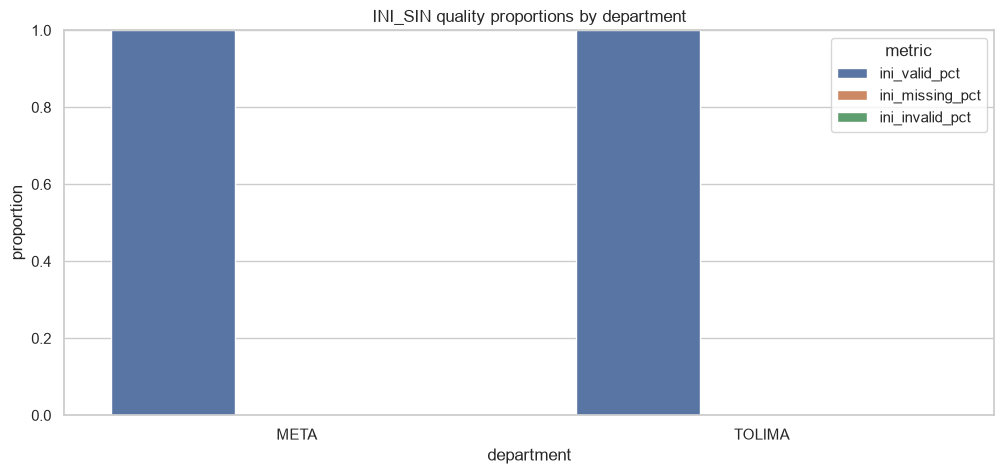

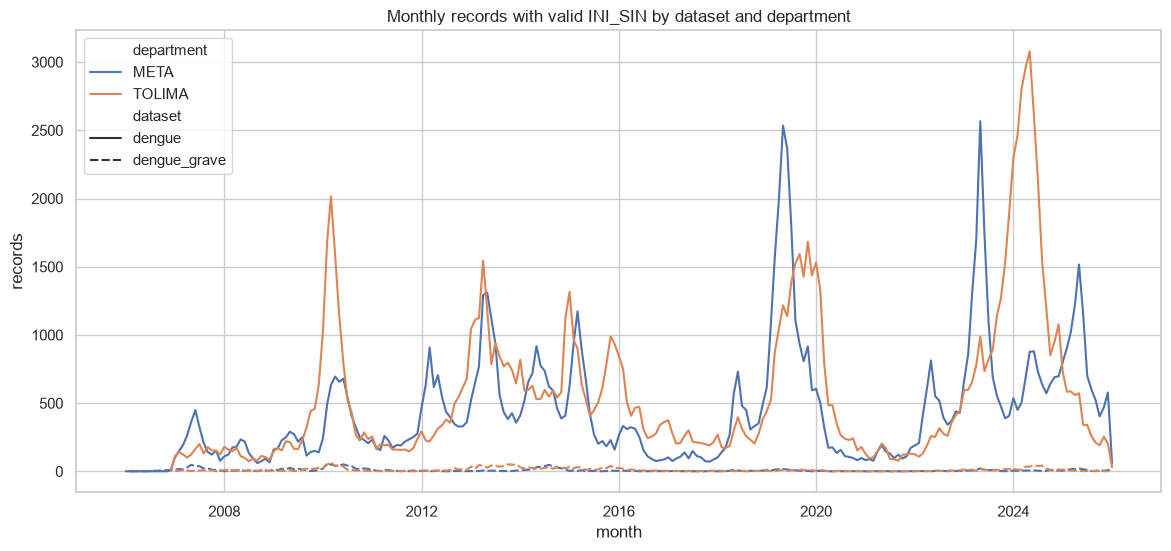

In [17]:
display(Markdown("### Municipality-level coverage and date quality (sample)"))
municipal_view = municipal_df.copy()
municipal_view["valid_ini_rate"] = municipal_view["records_valid_ini_sin"] / municipal_view["records_total"]
display(
    municipal_view
    .sort_values(["dataset", "department", "records_total"], ascending=[True, True, False])
    .groupby(["dataset", "department"], group_keys=False)
    .head(15)
)


display(Markdown("### Temporal distribution of missing/invalid `INI_SIN` by `FEC_NOT` month (sample)"))
if not temporal_problem_df.empty:
    display(
        temporal_problem_df
        .groupby(["dataset", "department", "problem_status"], as_index=False)["count"]
        .sum()
        .sort_values(["dataset", "department", "problem_status"]) 
    )
else:
    display(Markdown("No temporal problem rows available under current filters."))

quality_plot_df = quality_df.copy()
quality_plot_df = quality_plot_df.melt(
    id_vars=["dataset", "department"],
    value_vars=["ini_valid_pct", "ini_missing_pct", "ini_invalid_pct"],
    var_name="metric",
    value_name="value",
)

plt.figure(figsize=(12, 5))
sns.barplot(data=quality_plot_df, x="department", y="value", hue="metric", errorbar=None)
plt.title("INI_SIN quality proportions by department")
plt.ylabel("proportion")
plt.ylim(0, 1)
plt.show()

if not monthly_df.empty:
    monthly_plot = monthly_df.copy()
    monthly_plot["month"] = pd.PeriodIndex(monthly_plot["month"], freq="M").to_timestamp()
    plt.figure(figsize=(14, 6))
    sns.lineplot(
        data=monthly_plot,
        x="month",
        y="records_with_valid_ini_sin",
        hue="department",
        style="dataset",
        markers=False,
    )
    plt.title("Monthly records with valid INI_SIN by dataset and department")
    plt.ylabel("records")
    plt.xlabel("month")
    plt.show()

In [18]:
def analyze_climate_file(
    path: Path,
    scope_mpio_codes: set[str],
    overlap_start: pd.Timestamp,
    overlap_end: pd.Timestamp,
    chunk_size: int = 250_000,
):
    stats = Counter()
    variable_missing = Counter()
    duplicate_key_counter = Counter()

    muni_state = defaultdict(lambda: {
        "department": None,
        "municipality_name": None,
        "rows": 0,
        "valid_dates": set(),
        "min_date": None,
        "max_date": None,
        "rows_all_climate_missing": 0,
    })

    global_min_date = None
    global_max_date = None

    reader = pd.read_csv(
        path,
        usecols=CLIMATE_USECOLS,
        dtype=str,
        chunksize=chunk_size,
        low_memory=True,
    )

    for chunk in reader:
        dept_code = normalize_text_series(chunk["dpto_ccdgo"]).str.zfill(2).str[-2:]
        mpio_code = normalize_text_series(chunk["mpio_cdpmp"]).str.zfill(5).str[-5:]
        dept_name = normalize_name_series(chunk["dpto_cnmbr"])
        mpio_name = normalize_name_series(chunk["mpio_cnmbr"])

        in_scope = dept_code.isin(TARGET_DPTO_CODES.keys()) & mpio_code.isin(scope_mpio_codes)
        sub = chunk[in_scope].copy()
        if sub.empty:
            continue

        sub_dept_code = dept_code[in_scope]
        sub_mpio_code = mpio_code[in_scope]
        sub_dept_name = dept_name[in_scope]
        sub_mpio_name = mpio_name[in_scope]

        date_series = normalize_text_series(sub["date"])
        date_dt = pd.to_datetime(date_series, format="%Y-%m-%d", errors="coerce")

        stats["rows_in_scope"] += len(sub)
        stats["date_invalid_or_missing"] += int(date_dt.isna().sum())

        valid_date_mask = date_dt.notna()

        for var in CLIMATE_VARS:
            var_s = normalize_text_series(sub[var])
            variable_missing[var] += int((var_s == "").sum())

        all_missing_mask = np.ones(len(sub), dtype=bool)
        for var in CLIMATE_VARS:
            all_missing_mask &= normalize_text_series(sub[var]).eq("").to_numpy()
        stats["rows_all_climate_vars_missing"] += int(all_missing_mask.sum())

        valid_sub = pd.DataFrame(
            {
                "department": sub_dept_name.map({"META": "META", "TOLIMA": "TOLIMA"}).fillna(sub_dept_code.map(TARGET_DPTO_CODES)),
                "mpio_code": sub_mpio_code,
                "mpio_name": sub_mpio_name,
                "date": date_dt,
                "all_missing": all_missing_mask,
            }
        )
        valid_sub = valid_sub[valid_date_mask].copy()

        if valid_sub.empty:
            continue

        local_min = valid_sub["date"].min()
        local_max = valid_sub["date"].max()
        global_min_date = local_min if global_min_date is None else min(global_min_date, local_min)
        global_max_date = local_max if global_max_date is None else max(global_max_date, local_max)

        for row in valid_sub.itertuples(index=False):
            key = (row.department, row.mpio_code)
            state = muni_state[key]
            state["department"] = row.department
            state["municipality_name"] = row.mpio_name
            state["rows"] += 1
            state["valid_dates"].add(row.date.date())
            state["min_date"] = row.date if state["min_date"] is None else min(state["min_date"], row.date)
            state["max_date"] = row.date if state["max_date"] is None else max(state["max_date"], row.date)
            state["rows_all_climate_missing"] += int(row.all_missing)
            duplicate_key_counter[(row.department, row.mpio_code, row.date.date())] += 1

    overlap_dates = pd.date_range(overlap_start, overlap_end, freq="D") if overlap_start <= overlap_end else pd.DatetimeIndex([])
    overlap_date_set = set(overlap_dates.date)

    muni_rows = []
    for (dept, code), state in muni_state.items():
        existing_overlap_dates = len(state["valid_dates"].intersection(overlap_date_set))
        missing_overlap_dates = len(overlap_date_set) - existing_overlap_dates if len(overlap_date_set) else np.nan
        muni_rows.append(
            {
                "department": dept,
                "municipality_code_full": code,
                "municipality_name": state["municipality_name"],
                "rows": state["rows"],
                "date_min": state["min_date"],
                "date_max": state["max_date"],
                "unique_dates": len(state["valid_dates"]),
                "missing_dates_in_overlap_window": missing_overlap_dates,
                "rows_all_climate_missing": state["rows_all_climate_missing"],
                "rows_all_climate_missing_pct": state["rows_all_climate_missing"] / state["rows"] if state["rows"] else np.nan,
            }
        )

    muni_df = pd.DataFrame(muni_rows)

    duplicate_rows = sum(1 for _, count in duplicate_key_counter.items() if count > 1)
    duplicate_extra_rows = sum((count - 1) for count in duplicate_key_counter.values() if count > 1)

    variable_missing_df = pd.DataFrame(
        {
            "variable": CLIMATE_VARS,
            "missing_count": [variable_missing[v] for v in CLIMATE_VARS],
            "rows_in_scope": stats["rows_in_scope"],
        }
    )
    variable_missing_df["missing_pct"] = variable_missing_df["missing_count"] / variable_missing_df["rows_in_scope"]

    summary_df = pd.DataFrame(
        [
            {
                "rows_in_scope": stats["rows_in_scope"],
                "invalid_or_missing_date_rows": stats["date_invalid_or_missing"],
                "date_min": global_min_date,
                "date_max": global_max_date,
                "rows_all_climate_vars_missing": stats["rows_all_climate_vars_missing"],
                "duplicate_municipality_date_values": duplicate_rows,
                "duplicate_extra_rows": duplicate_extra_rows,
                "overlap_start": overlap_start,
                "overlap_end": overlap_end,
                "overlap_days": len(overlap_date_set),
            }
        ]
    )

    return summary_df, muni_df.sort_values(["department", "municipality_code_full"]), variable_missing_df


epi_windows = [
    (epi_results[k]["window_min_valid_ini"], epi_results[k]["window_max_valid_ini"])
    for k in epi_results
    if epi_results[k]["window_min_valid_ini"] is not None and epi_results[k]["window_max_valid_ini"] is not None
]

if epi_windows:
    epi_overlap_start = max(w[0] for w in epi_windows)
    epi_overlap_end = min(w[1] for w in epi_windows)
else:
    epi_overlap_start = pd.Timestamp("1900-01-01")
    epi_overlap_end = pd.Timestamp("1900-01-01")

provisional_summary_df, provisional_muni_df, provisional_missing_df = analyze_climate_file(
    data_paths["climate"],
    scope_mpio_codes=validated_mpio_codes,
    overlap_start=epi_overlap_start,
    overlap_end=epi_overlap_end,
)

climate_min = provisional_summary_df.loc[0, "date_min"]
climate_max = provisional_summary_df.loc[0, "date_max"]
common_start = max(epi_overlap_start, climate_min) if pd.notna(climate_min) else epi_overlap_start
common_end = min(epi_overlap_end, climate_max) if pd.notna(climate_max) else epi_overlap_end

climate_summary_df, climate_muni_df, climate_missing_df = analyze_climate_file(
    data_paths["climate"],
    scope_mpio_codes=validated_mpio_codes,
    overlap_start=common_start,
    overlap_end=common_end,
)


display(Markdown("### Climate coverage summary (Tolima/Meta residence municipalities only)"))
display(climate_summary_df)

display(Markdown("### Climate variable missingness"))
display(climate_missing_df)

display(Markdown("### Climate municipality coverage (sample)"))
display(
    climate_muni_df
    .sort_values(["department", "rows"], ascending=[True, False])
    .groupby("department", group_keys=False)
    .head(20)
)

### Climate coverage summary (Tolima/Meta residence municipalities only)

,rows_in_scope,invalid_or_missing_date_rows,date_min,date_max,rows_all_climate_vars_missing,duplicate_municipality_date_values,duplicate_extra_rows,overlap_start,overlap_end,overlap_days
0,525084,0,2007-01-01,2025-12-31,0,0,0,2007-01-01,2025-12-31,6940


### Climate variable missingness

,variable,missing_count,rows_in_scope,missing_pct
0,rain_mm_day,0,525084,0.0
1,temp_mean_c,0,525084,0.0
2,dewpoint_mean_c,0,525084,0.0
3,soil_water_l1_mean,0,525084,0.0
4,surface_runoff_mm_day,0,525084,0.0
5,total_evaporation_mm_day_ecmwf,0,525084,0.0
6,wind_u_mean_ms,0,525084,0.0
7,wind_v_mean_ms,0,525084,0.0
8,solar_radiation_mj_m2_day,0,525084,0.0


### Climate municipality coverage (sample)

,department,municipality_code_full,municipality_name,rows,date_min,date_max,unique_dates,missing_dates_in_overlap_window,rows_all_climate_missing,rows_all_climate_missing_pct
0,META,50001,VILLAVICENCIO,6909,2007-01-01,2025-12-31,6909,31,0,0.0
1,META,50006,ACACIAS,6909,2007-01-01,2025-12-31,6909,31,0,0.0
2,META,50110,BARRANCA DE UPIA,6909,2007-01-01,2025-12-31,6909,31,0,0.0
23,META,50124,CABUYARO,6909,2007-01-01,2025-12-31,6909,31,0,0.0
3,META,50150,CASTILLA LA NUEVA,6909,2007-01-01,2025-12-31,6909,31,0,0.0
4,META,50223,CUBARRAL,6909,2007-01-01,2025-12-31,6909,31,0,0.0
5,META,50226,CUMARAL,6909,2007-01-01,2025-12-31,6909,31,0,0.0
6,META,50245,EL CALVARIO,6909,2007-01-01,2025-12-31,6909,31,0,0.0
7,META,50251,EL CASTILLO,6909,2007-01-01,2025-12-31,6909,31,0,0.0
8,META,50270,EL DORADO,6909,2007-01-01,2025-12-31,6909,31,0,0.0


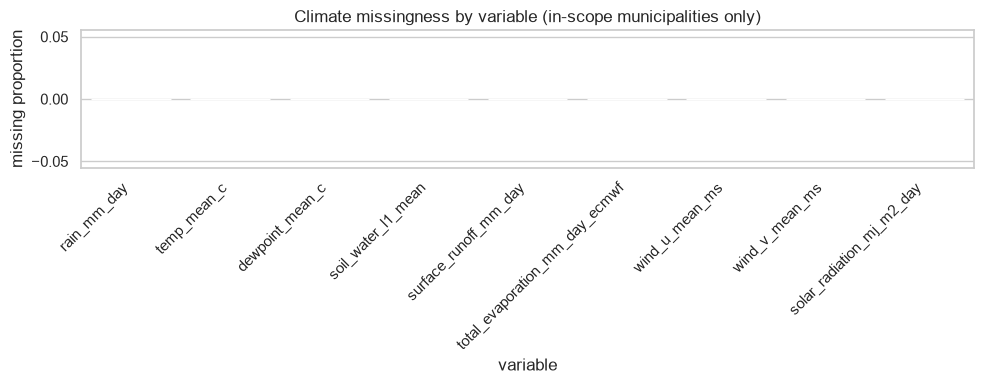

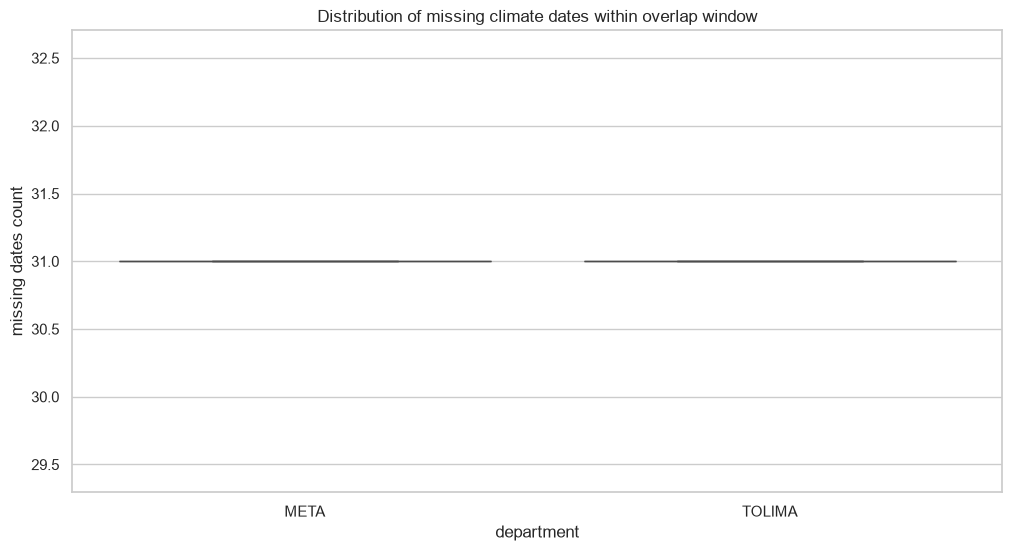

### Municipalities with highest missing climate dates (sample)

,department,municipality_code_full,municipality_name,missing_dates_in_overlap_window
0,META,50001,VILLAVICENCIO,31
1,META,50006,ACACIAS,31
2,META,50110,BARRANCA DE UPIA,31
23,META,50124,CABUYARO,31
3,META,50150,CASTILLA LA NUEVA,31
4,META,50223,CUBARRAL,31
5,META,50226,CUMARAL,31
6,META,50245,EL CALVARIO,31
7,META,50251,EL CASTILLO,31
8,META,50270,EL DORADO,31


### Coverage checks status

,check,state,details
0,Official municipality inventory for completene...,BLOCKED,No official municipality inventory file was fo...
1,Residence geography filtering,PASS,Filtering used COD_DPTO_R/COD_MUN_R and reside...
2,Automatic INI_SIN replacement by FEC_NOT,PASS,No automatic substitution policy was applied.


In [19]:
plt.figure(figsize=(10, 4))
sns.barplot(data=climate_missing_df, x="variable", y="missing_pct", color="#3D7EA6")
plt.xticks(rotation=45, ha="right")
plt.ylabel("missing proportion")
plt.title("Climate missingness by variable (in-scope municipalities only)")
plt.tight_layout()
plt.show()

if not climate_muni_df.empty:
    coverage_plot = climate_muni_df.copy()
    coverage_plot = coverage_plot.sort_values(["department", "missing_dates_in_overlap_window"], ascending=[True, False])

    plt.figure(figsize=(12, 6))
    sns.boxplot(data=coverage_plot, x="department", y="missing_dates_in_overlap_window")
    plt.title("Distribution of missing climate dates within overlap window")
    plt.ylabel("missing dates count")
    plt.show()

    top_missing = (
        coverage_plot
        .groupby("department", group_keys=False)
        .head(10)
        [["department", "municipality_code_full", "municipality_name", "missing_dates_in_overlap_window"]]
    )
    display(Markdown("### Municipalities with highest missing climate dates (sample)"))
    display(top_missing)

inventory_status = pd.DataFrame(
    [
        {
            "check": "Official municipality inventory for completeness baseline",
            "state": "BLOCKED",
            "details": "No official municipality inventory file was found in this repository for direct completeness benchmarking.",
        },
        {
            "check": "Residence geography filtering",
            "state": "PASS",
            "details": "Filtering used COD_DPTO_R/COD_MUN_R and residence labels; occurrence geography was not used for scope filtering.",
        },
        {
            "check": "Automatic INI_SIN replacement by FEC_NOT",
            "state": "PASS",
            "details": "No automatic substitution policy was applied.",
        },
    ]
)

display(Markdown("### Coverage checks status"))
display(inventory_status)

In [20]:
evidence_states = pd.DataFrame(
    [
        {
            "topic": "CSV structure and required headers",
            "state": "PASS",
            "evidence": "Header checks for dengue, dengue_grave, and climate files.",
        },
        {
            "topic": "Residence-based scope balance",
            "state": "PASS",
            "evidence": "Total/in-scope/outside/indeterminate balances computed per epidemiological file.",
        },
        {
            "topic": "INI_SIN quality and temporal diagnostics",
            "state": "PASS",
            "evidence": "Valid/missing/invalid counts, future dates, delay distributions, municipal monthly coverage.",
        },
        {
            "topic": "Climate coverage for validated municipalities",
            "state": "PASS",
            "evidence": "Date coverage, missingness by variable, overlap-window date gaps, duplicate municipality-date checks.",
        },
        {
            "topic": "Official municipality inventory completeness benchmark",
            "state": "BLOCKED",
            "evidence": "No official inventory file found in-repo for definitive completeness denominator.",
        },
        {
            "topic": "Final target definition / modeling decisions",
            "state": "UNVERIFIED",
            "evidence": "Out of scope for this bounded Stage 2 EDA increment.",
        },
    ]
)

display(Markdown("### Evidence states"))
display(evidence_states)

key_metrics = quality_df[[
    "dataset", "department", "records_in_scope", "ini_valid_count", "ini_missing_count", "ini_invalid_count",
    "ini_future_vs_cutoff_count", "ini_after_fec_not_count",
]].copy()

display(Markdown("### Key metrics for report update"))
display(key_metrics)

print("Notebook execution complete for Stage 2 bounded EDA increment.")

### Evidence states

,topic,state,evidence
0,CSV structure and required headers,PASS,"Header checks for dengue, dengue_grave, and cl..."
1,Residence-based scope balance,PASS,Total/in-scope/outside/indeterminate balances ...
2,INI_SIN quality and temporal diagnostics,PASS,"Valid/missing/invalid counts, future dates, de..."
3,Climate coverage for validated municipalities,PASS,"Date coverage, missingness by variable, overla..."
4,Official municipality inventory completeness b...,BLOCKED,No official inventory file found in-repo for d...
5,Final target definition / modeling decisions,UNVERIFIED,Out of scope for this bounded Stage 2 EDA incr...


### Key metrics for report update

,dataset,department,records_in_scope,ini_valid_count,ini_missing_count,ini_invalid_count,ini_future_vs_cutoff_count,ini_after_fec_not_count
0,dengue,META,106457,106451,6,0,0,3597
1,dengue,TOLIMA,129044,129043,1,0,0,4959
2,dengue_grave,META,1963,1963,0,0,0,0
3,dengue_grave,TOLIMA,2656,2656,0,0,0,0


Notebook execution complete for Stage 2 bounded EDA increment.


## Results, limitations, and review point

### Observations
- Results in this notebook are descriptive and scoped to Stage 2 data understanding.
- Dengue and severe dengue records were analyzed separately.
- Climate review was restricted to validated Tolima/Meta residence municipality codes.

### Limitations
- No official municipality inventory file was found in-repo for full territorial completeness benchmarking.
- This notebook does not perform cleaning, imputation, deduplication, integration, endemic-channel construction, or modeling.

### Pending decisions
- Final rule set for epidemiological-year consistency interpretation and historical applicability.
- Final municipality eligibility criteria for downstream target/model stages.
- Training strategy choice (shared vs departmental vs municipal) remains open.

**Stop point:** Stage 2 remains open and G2 is not approved.